# 01 — Audit Dataset EBHI-SEG

## Tujuan dan batas analisis

**Pertanyaan:** apakah pasangan citra dan *reference mask* pada dataset EBHI-SEG lengkap, bagaimana *encoding* nilai piksel *mask* mentah, dan apakah terdapat duplikasi piksel yang memengaruhi kohort eksperimen?

**Artefak input:**
- `data/metadata/manifest.csv`
- `data/metadata/mask_audit.csv`
- `data/metadata/image_hashes.csv`
- `data/metadata/split_manifest.csv` dan `data/metadata/split_manifest.sha256`
- Opsional: citra mentah `data/raw/EBHI-SEG/` (hanya subset `train` untuk pemeriksaan dekode dan *overlay* representatif)

**Batas eksekusi:** notebook ini membaca hasil audit tersimpan tanpa memindai ulang seluruh 2.228 file mentah, tidak mengubah artefak metadata, dan tidak menyentuh citra *held-out* `test`.

In [1]:
%matplotlib inline

from pathlib import Path
import platform

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

from ebhi_dip import (
    REFERENCE_THRESHOLD,
    compute_histogram_1d,
    configure_notebook_style,
    find_project_root,
    finish_figure,
    has_raw_dataset,
    load_raw_mask,
    load_rgb,
    load_split_manifest,
    resolve_manifest_path,
    sha256_bytes,
    uint8_bin_edges,
    verify_frozen_split,
)

PROJECT_ROOT_OVERRIDE = None
DATA_ROOT_OVERRIDE = None
EXPORT_FIGURES = False

ROOT = find_project_root(override=PROJECT_ROOT_OVERRIDE)
SPLIT_SHA = verify_frozen_split(ROOT)
RAW_AVAILABLE = has_raw_dataset(ROOT, data_root_override=DATA_ROOT_OVERRIDE)
configure_notebook_style()

source_files = {
    "manifest": ROOT / "data/metadata/manifest.csv",
    "mask_audit": ROOT / "data/metadata/mask_audit.csv",
    "image_hashes": ROOT / "data/metadata/image_hashes.csv",
    "split_manifest": ROOT / "data/metadata/split_manifest.csv",
}
input_hashes_before = {name: sha256_bytes(path) for name, path in source_files.items()}

display(
    pd.DataFrame(
        {
            "komponen": ["Python", "NumPy", "pandas", "Matplotlib", "Raw dataset tersedia"],
            "nilai": [
                platform.python_version(),
                np.__version__,
                pd.__version__,
                matplotlib.__version__,
                str(RAW_AVAILABLE),
            ],
        }
    )
)

,komponen,nilai
0,Python,3.14.0
1,NumPy,2.5.4
2,pandas,3.1.1
3,Matplotlib,3.11.2
4,Raw dataset tersedia,True


## 1. Kelengkapan pasangan citra dan *reference mask*

Setiap citra histopatologi pada `image/` diperiksa terhadap pasangan *mask* bernama sama pada `label/` di kategori yang sama.

In [2]:
manifest = pd.read_csv(source_files["manifest"], encoding="utf-8-sig")
mask_audit = pd.read_csv(source_files["mask_audit"], encoding="utf-8-sig")
image_hashes = pd.read_csv(source_files["image_hashes"], encoding="utf-8-sig")
split_df = load_split_manifest(ROOT, verify=False)

pairing_summary = (
    manifest.assign(
        is_paired=manifest["pair_status"].eq("paired"),
        is_missing=manifest["pair_status"].eq("missing_mask"),
    )
    .groupby("category", observed=True)
    .agg(
        total_images=("sample_id", "size"),
        paired_images=("is_paired", "sum"),
        missing_masks=("is_missing", "sum"),
    )
)
pairing_summary.loc["TOTAL"] = pairing_summary.sum()
display(pairing_summary)

,total_images,paired_images,missing_masks
category,,,
Adenocarcinoma,795,795,0
High-grade IN,186,186,0
Low-grade IN,639,637,2
Normal,76,76,0
Polyp,474,474,0
Serrated adenoma,58,58,0
TOTAL,2228,2226,2


In [3]:
unpaired_rows = manifest.loc[manifest["pair_status"] != "paired", ["sample_id", "category", "pair_status"]]
display(unpaired_rows)

,sample_id,category,pair_status
1001,Low-grade IN/GT2012149-2-400-001,Low-grade IN,missing_mask
1152,Low-grade IN/GTGT2012149-2-400-001,Low-grade IN,missing_mask


In [4]:
assert int(pairing_summary.loc["TOTAL", "total_images"]) == 2228
assert int(pairing_summary.loc["TOTAL", "paired_images"]) == 2226
assert len(unpaired_rows) == 2

**Temuan pasangan file.** Dari 2.228 citra asli lintas enam kategori, 2.226 citra memiliki pasangan *mask* lengkap. Dua file tanpa *mask* berasal dari `Low-grade IN` (`GT2012149-2-400-001` dan `GTGT2012149-2-400-001`) dan dikeluarkan dari kohort berpasangan.

## 2. Pemeriksaan sidik jari piksel dan duplikasi

Sidik jari `pixel_sha256` dihitung dari piksel RGB hasil dekode (`224×224`), sehingga mendeteksi duplikasi isi citra meskipun nama file atau kompresi PNG berbeda.

In [5]:
hash_counts = image_hashes.groupby("pixel_sha256", observed=True).agg(
    copy_count=("sample_id", "size"),
    category_count=("category", "nunique"),
    sample_ids=("sample_id", lambda s: " | ".join(s)),
)
dup_groups = hash_counts.loc[hash_counts["copy_count"] > 1].copy()

dup_overview = pd.DataFrame(
    [
        {"metrik": "Total citra dipindai", "jumlah": len(image_hashes)},
        {"metrik": "Sidik jari piksel unik", "jumlah": len(hash_counts)},
        {"metrik": "Grup duplikat (>1 file)", "jumlah": len(dup_groups)},
        {"metrik": "Total file dalam grup duplikat", "jumlah": int(dup_groups["copy_count"].sum())},
        {"metrik": "Grup duplikat lintas kategori", "jumlah": int((dup_groups["category_count"] > 1).sum())},
    ]
)
display(dup_overview)

,metrik,jumlah
0,Total citra dipindai,2228
1,Sidik jari piksel unik,2227
2,Grup duplikat (>1 file),1
3,Total file dalam grup duplikat,2
4,Grup duplikat lintas kategori,0


In [6]:
unpaired_hashes = image_hashes.loc[image_hashes["pair_status"] != "paired", "pixel_sha256"].unique()
unpaired_cluster = image_hashes.loc[
    image_hashes["pixel_sha256"].isin(unpaired_hashes),
    ["sample_id", "category", "pair_status", "pixel_sha256"],
]
display(unpaired_cluster)

,sample_id,category,pair_status,pixel_sha256
1001,Low-grade IN/GT2012149-2-400-001,Low-grade IN,missing_mask,27aff0a87f6ab6f0dcda48cf485f7308cb4d9c3e374d4a...
1152,Low-grade IN/GTGT2012149-2-400-001,Low-grade IN,missing_mask,27aff0a87f6ab6f0dcda48cf485f7308cb4d9c3e374d4a...


**Makna temuan duplikasi.** Kedua citra `missing_mask` pada `Low-grade IN` berbagi sidik jari piksel yang sama persis, sehingga tidak merupakan sampel histopatologi unik yang terpisah. Tidak ada duplikasi piksel lintas kategori diagnostik (`0` grup lintas kategori).

## 3. Audit *encoding* *mask* mentah dan cakupan *foreground*

*Mask* mentah disimpan sebagai citra *grayscale* 8-bit (`0–255`). Kontrak referensi proyek menetapkan piksel *foreground* sebagai `mask >= 128` tanpa memodifikasi file asli.

In [7]:
assert len(mask_audit) == 2226
pure_binary = int((mask_audit["gray_pixels"] == 0).sum())
with_intermediate = int((mask_audit["gray_pixels"] > 0).sum())
empty_fg = int((mask_audit["foreground_pixels"] == 0).sum())
full_fg = mask_audit.loc[mask_audit["foreground_pixels"] == 224 * 224].copy()
const_full_fg = full_fg.loc[full_fg["minimum"] == full_fg["maximum"]]

encoding_summary = pd.DataFrame(
    [
        {"pemeriksaan": "Pasangan mask diaudit", "hasil": len(mask_audit)},
        {"pemeriksaan": "Hanya berisi nilai {0, 255}", "hasil": pure_binary},
        {"pemeriksaan": "Memiliki piksel abu-abu menengah (1..254)", "hasil": with_intermediate},
        {"pemeriksaan": "Seluruhnya background pada mask >= 128", "hasil": empty_fg},
        {"pemeriksaan": "Seluruhnya foreground (50.176 piksel) pada mask >= 128", "hasil": len(full_fg)},
        {"pemeriksaan": "Full-foreground konstan vs non-konstan", "hasil": f"{len(const_full_fg)} vs {len(full_fg) - len(const_full_fg)}"},
    ]
)
display(encoding_summary)

,pemeriksaan,hasil
0,Pasangan mask diaudit,2226
1,"Hanya berisi nilai {0, 255}",19
2,Memiliki piksel abu-abu menengah (1..254),2207
3,Seluruhnya background pada mask >= 128,0
4,Seluruhnya foreground (50.176 piksel) pada mas...,35
5,Full-foreground konstan vs non-konstan,33 vs 2


In [8]:
cat_mask_stats = mask_audit.groupby("category", observed=True).agg(
    images=("sample_id", "size"),
    mean_gray_pct=("gray_percentage", "mean"),
    max_gray_pct=("gray_percentage", "max"),
    min_fg_pct=("foreground_percentage", "min"),
    median_fg_pct=("foreground_percentage", "median"),
    mean_fg_pct=("foreground_percentage", "mean"),
    max_fg_pct=("foreground_percentage", "max"),
).round(2)
cat_mask_stats["full_fg_masks"] = (
    full_fg.groupby("category", observed=True).size().reindex(cat_mask_stats.index, fill_value=0)
)
display(cat_mask_stats)

,images,mean_gray_pct,max_gray_pct,min_fg_pct,median_fg_pct,mean_fg_pct,max_fg_pct,full_fg_masks
category,,,,,,,,
Adenocarcinoma,795,20.39,100.00,13.79,68.13,67.03,100.00,35
High-grade IN,186,4.96,9.45,36.66,68.90,68.38,91.13,0
Low-grade IN,637,4.92,9.85,30.13,66.71,65.62,92.02,0
Normal,76,5.49,9.28,42.87,61.62,60.86,86.12,0
Polyp,474,4.93,7.66,21.28,54.05,53.69,80.39,0
Serrated adenoma,58,3.86,7.83,34.58,64.28,63.85,91.38,0


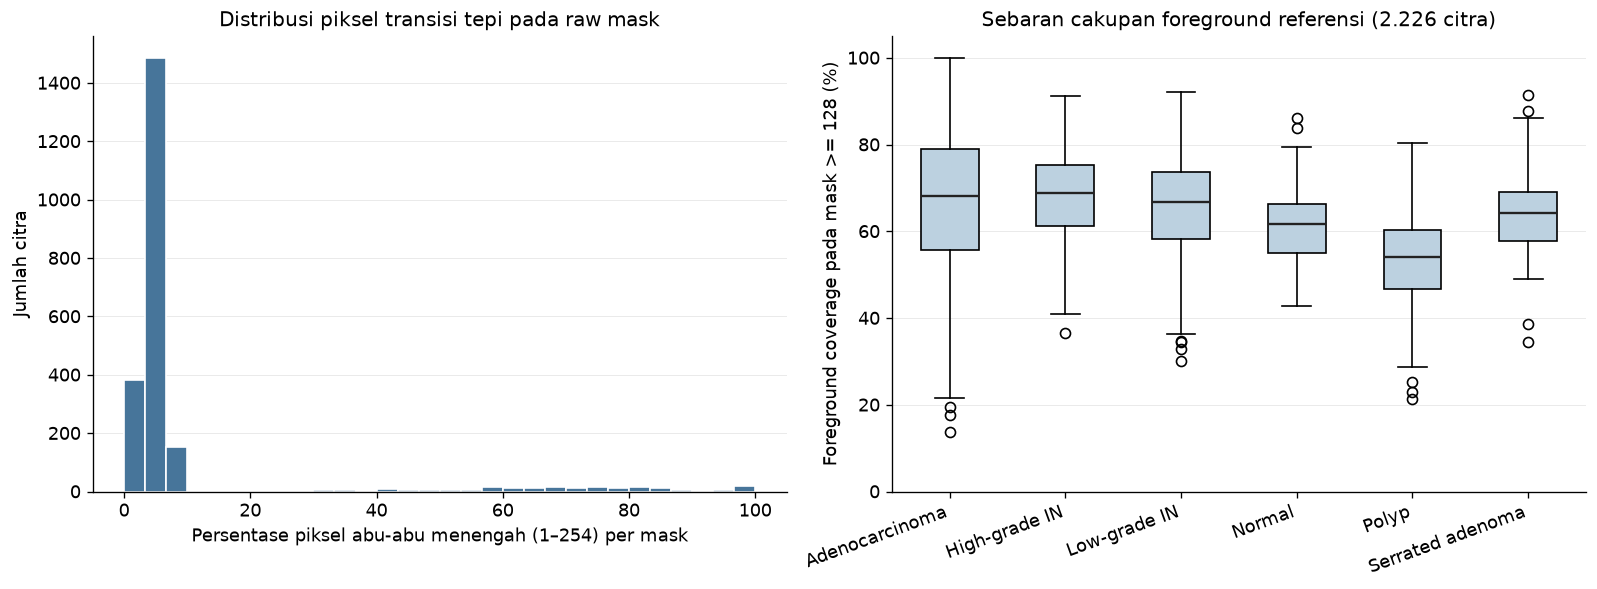

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13.2, 4.8), layout="constrained")
axes[0].hist(mask_audit["gray_percentage"], bins=30, color="#47759A", edgecolor="white")
axes[0].set_xlabel("Persentase piksel abu-abu menengah (1–254) per mask")
axes[0].set_ylabel("Jumlah citra")
axes[0].set_title("Distribusi piksel transisi tepi pada raw mask")
axes[0].grid(axis="y", color="#EAEAEA", linewidth=0.6)

categories = list(cat_mask_stats.index)
box_vals = [mask_audit.loc[mask_audit["category"].eq(c), "foreground_percentage"].to_numpy() for c in categories]
bp = axes[1].boxplot(
    box_vals,
    tick_labels=categories,
    patch_artist=True,
    medianprops={"color": "#222222", "linewidth": 1.4},
)
for patch in bp["boxes"]:
    patch.set_facecolor("#BCD1E0")
plt.setp(axes[1].get_xticklabels(), rotation=20, ha="right")
axes[1].set_ylim(0, 105)
axes[1].set_ylabel("Foreground coverage pada mask >= 128 (%)")
axes[1].set_title("Sebaran cakupan foreground referensi (2.226 citra)")
axes[1].grid(axis="y", color="#EAEAEA", linewidth=0.6)

export_target = (ROOT / "reports/figures/01_mask_audit_overview.png") if EXPORT_FIGURES else None
finish_figure(fig, export_path=export_target)

**Interpretasi *encoding* *mask*.**
- **Observasi:** sebagian besar *mask* memiliki persentase kecil piksel bernilai `1–254`, tidak ada *mask* kosong (`0%` *foreground*), dan terdapat 35 *full-foreground masks* (`100%` *foreground* setelah `mask >= 128`, didominasi `Normal` dan `Adenocarcinoma`).
- **Dugaan penyebab:** nilai abu-abu menengah terkonsentrasi di sepanjang batas objek akibat *anti-aliasing* atau ekspor anotasi raster, sehingga **bukan bukti otomatis kerusakan data**.
- **Keputusan kontrak:** seluruh 2.226 pasangan (termasuk 35 *full-foreground masks*) dipertahankan dan dibinerisasi secara konsisten dengan `mask >= 128`.

## 4. Pemeriksaan dekode dan *overlay* sampel `train` representatif

Untuk memverifikasi keselarasan spasial tanpa menyentuh subset `val` maupun `test`, bagian ini menampilkan dua citra dari `train`: sampel dengan proporsi piksel abu-abu *mask* tertinggi dan sampel *full-foreground*.

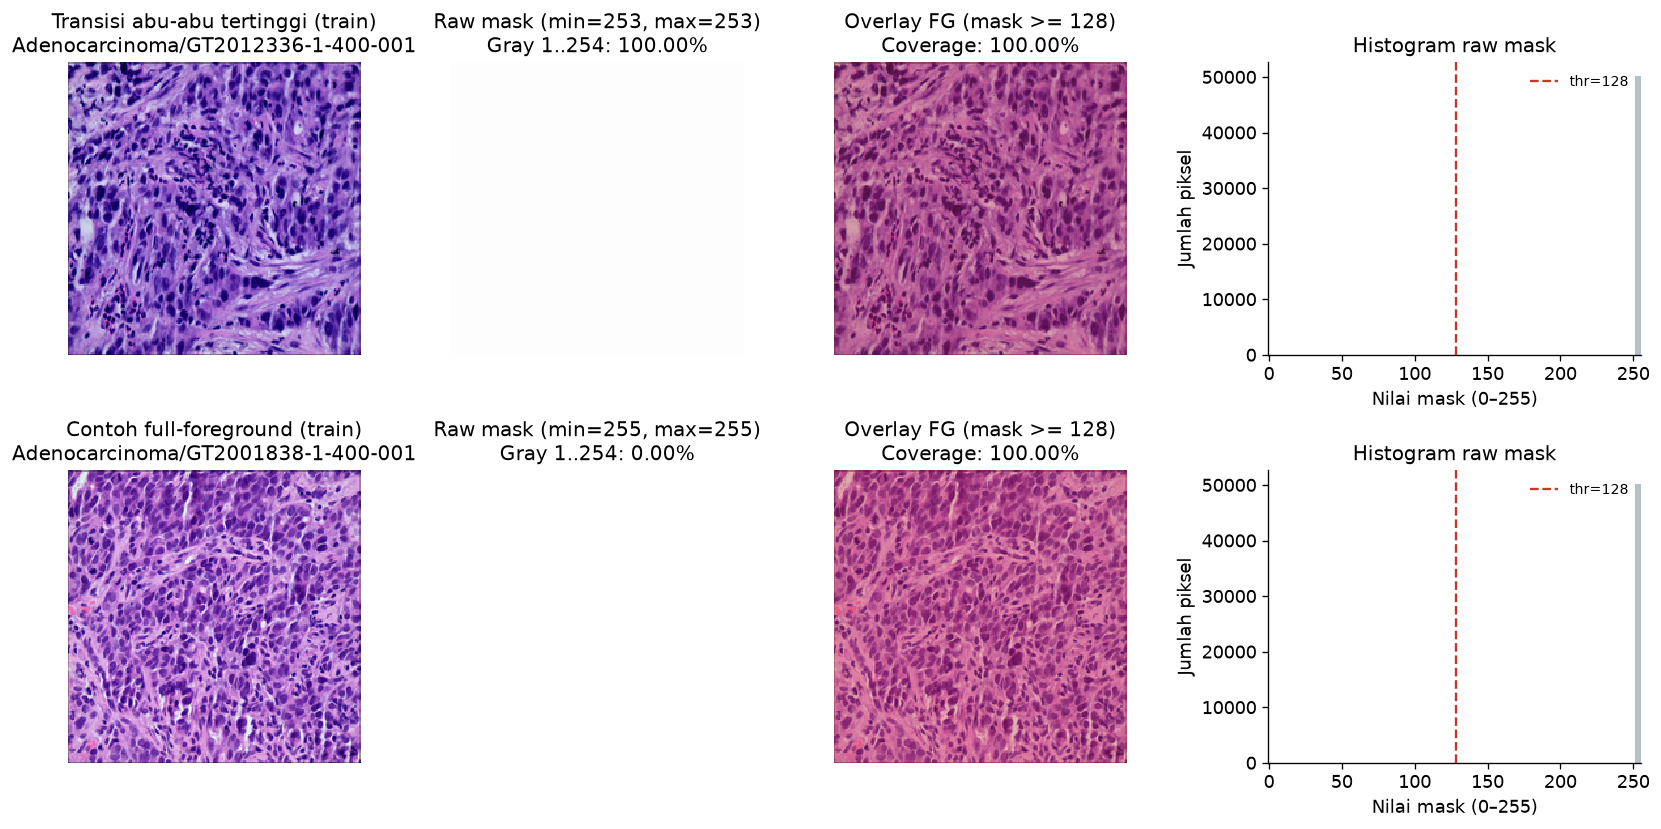

In [10]:
train_audit = mask_audit.merge(
    split_df.loc[split_df["split"].eq("train"), ["sample_id", "image_path", "mask_path", "split"]],
    on="sample_id",
    how="inner",
)
high_gray_row = train_audit.sort_values(["gray_percentage", "sample_id"], ascending=[False, True]).iloc[0]
full_fg_row = train_audit.loc[train_audit["foreground_pixels"] == 224 * 224].sort_values("sample_id").iloc[0]

if not RAW_AVAILABLE:
    display(
        Markdown(
            "> **Status citra mentah:** `data/raw/EBHI-SEG/` tidak ditemukan pada *checkout* ini. "
            "Pemeriksaan dekode piksel dan *overlay* citra dilewati tanpa membuat *output* sintetis."
        )
    )
else:
    u8_edges = uint8_bin_edges(64)
    fig, axes = plt.subplots(2, 4, figsize=(13.6, 6.8), layout="constrained")
    sample_specs = [
        ("Transisi abu-abu tertinggi (train)", high_gray_row),
        ("Contoh full-foreground (train)", full_fg_row),
    ]
    for row_idx, (label, rec) in enumerate(sample_specs):
        img = load_rgb(resolve_manifest_path(ROOT, rec["image_path"], data_root_override=DATA_ROOT_OVERRIDE))
        raw_m = load_raw_mask(resolve_manifest_path(ROOT, rec["mask_path"], data_root_override=DATA_ROOT_OVERRIDE))
        assert img.shape == (224, 224, 3) and raw_m.shape == (224, 224)
        bin_m = raw_m >= REFERENCE_THRESHOLD

        overlay = img.astype(np.float32).copy()
        overlay[bin_m] = 0.65 * overlay[bin_m] + 0.35 * np.array([220.0, 50.0, 47.0], dtype=np.float32)
        overlay_u8 = np.clip(np.rint(overlay), 0, 255).astype(np.uint8)

        axes[row_idx, 0].imshow(img, interpolation="nearest")
        axes[row_idx, 0].set_title(f"{label}\n{rec['sample_id']}")
        axes[row_idx, 0].axis("off")

        axes[row_idx, 1].imshow(raw_m, cmap="gray", vmin=0, vmax=255, interpolation="nearest")
        axes[row_idx, 1].set_title(
            f"Raw mask (min={int(raw_m.min())}, max={int(raw_m.max())})\n"
            f"Gray 1..254: {float(rec['gray_percentage']):.2f}%"
        )
        axes[row_idx, 1].axis("off")

        axes[row_idx, 2].imshow(overlay_u8, interpolation="nearest")
        axes[row_idx, 2].set_title(f"Overlay FG (mask >= 128)\nCoverage: {100.0 * bin_m.mean():.2f}%")
        axes[row_idx, 2].axis("off")

        h_mask = compute_histogram_1d(raw_m, u8_edges)
        axes[row_idx, 3].stairs(h_mask["heights"], h_mask["edges"], fill=True, alpha=0.35, color="#34495E")
        axes[row_idx, 3].axvline(REFERENCE_THRESHOLD, color="#C0392B", linestyle="--", linewidth=1.4, label="thr=128")
        axes[row_idx, 3].set_xlim(-0.5, 255.5)
        axes[row_idx, 3].set_title("Histogram raw mask")
        axes[row_idx, 3].set_xlabel("Nilai mask (0–255)")
        axes[row_idx, 3].set_ylabel("Jumlah piksel")
        axes[row_idx, 3].legend(frameon=False, fontsize=8.5)

    export_target = (ROOT / "reports/figures/01_train_pair_overlays.png") if EXPORT_FIGURES else None
    finish_figure(fig, export_path=export_target)

## Ringkasan dan verifikasi integritas

- Kohort berpasangan berisi **2.226 citra** (`224×224` RGB dan *grayscale mask*), setelah mengeluarkan 2 file `Low-grade IN` tanpa *mask* yang juga merupakan duplikat piksel.
- Aturan binerisasi referensi `mask >= 128` menangani piksel transisi tepi secara seragam tanpa memodifikasi *raw files*.
- Cakupan *foreground* yang lebar (termasuk 35 *full-foreground masks*) menjelaskan mengapa kontrol konstan `all_foreground` wajib disertakan pada evaluasi segmentasi.

In [11]:
input_hashes_after = {name: sha256_bytes(path) for name, path in source_files.items()}
assert input_hashes_after == input_hashes_before, "Artefak input berubah saat notebook dijalankan."
print("Selesai: 2.226 pasangan teraudit; seluruh artefak metadata tetap utuh.")

Selesai: 2.226 pasangan teraudit; seluruh artefak metadata tetap utuh.
